# Part 1 — Acquisition & Storage
## Notebook 02. Storage benchmarks and reproducible evidence

**Objective.** Evaluate storage footprint and measured read performance of identical FDIC Financials records, and establish the physical benefits and costs of the 170-quarter production layout.

**Inputs.** The explicitly selected and verified acquisition stage from Notebook 01. No historical run IDs and no new FDIC requests are used.

**Measured designs.** Uncompressed flat CSV, flat Snappy Parquet and quarter-partitioned Snappy Parquet. Baseline CSV/Parquet workloads are complemented by controlled flat-versus-partitioned scans with physical fragment counts. The benchmark is executed on local Colab storage, not on a Drive-mount filesystem.

### 1. Mount Drive, select the pinned experiment and restore source code

The selected experiment pointer identifies a fixed source revision. This notebook does not search for the newest output directory.

In [1]:
from google.colab import drive
from pathlib import Path
import json, shutil, subprocess, sys

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/BFT65B_11230945")
pointer = json.loads((DRIVE_ROOT / "control" / "active_experiment.json").read_text())
EXPERIMENT_ID = pointer["experiment_id"]
config_path = DRIVE_ROOT / "experiments" / EXPERIMENT_ID / "experiment_config.lock.json"
GIT_COMMIT = json.loads(config_path.read_text())["git_commit"]
REPO_DIR = Path("/content/bft65b_code")
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(["git", "clone", "--quiet",
    "https://github.com/NguyenDuong58/11230945-NguyenBaDuong.git", str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "--quiet", GIT_COMMIT], check=True)
assert subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip() == GIT_COMMIT
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                str(REPO_DIR / "requirements.txt")], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))
print("Experiment:", EXPERIMENT_ID)
print("Git commit:", GIT_COMMIT)

Mounted at /content/drive
Experiment: experiment_20261116T115513Z_d23d2b10
Git commit: c5bad10b9199fe163ae7e1e1c1d9029a4be0c470


### 2. Check the storage implementation and input contract

The identical Parquet and CSV comparison files must be created from one verified source snapshot. All unit/integration tests are executed before using actual FDIC files.

In [2]:
import xml.etree.ElementTree as ET
from fdic_pipeline.project_flow import resolve_stage, stage_dir, HandoffError
from fdic_pipeline.workflow import acquisition_contract

xml = Path("/content/bft65b_part1_storage_tests.xml")
subprocess.run([sys.executable, "-m", "pytest", "-q", "-rs", "--junitxml", str(xml),
                str(REPO_DIR / "tests")], cwd=REPO_DIR, check=True)
suites = ET.parse(xml).getroot().findall(".//testsuite")
assert suites and all(int(x.get(k, 0)) == 0 for x in suites
                      for k in ("failures", "errors", "skipped"))
SOURCE = resolve_stage(DRIVE_ROOT, "acquisition")
SOURCE_DIR = SOURCE["path"]
CONTRACT = acquisition_contract(SOURCE_DIR)
assert CONTRACT["manifest_sha256"] == SOURCE["validation"]["source_manifest_sha256"]
assert CONTRACT["verification_report_sha256"] == SOURCE["validation"]["source_verification_sha256"]
print("Input: PASSED,", CONTRACT["quarters"], "quarters,", CONTRACT["financial_rows"], "rows")

Input: PASSED, 170 quarters, 1682616 rows


### 3. Prepare identical storage inputs on local disk

Each of the 170 production Parquet partitions is copied locally and validated against the source manifest. The CSV and flat Parquet files are created from exactly the same Arrow batches; equality of schema, record order, values and null masks is checked before any timing trial.

In [3]:
from fdic_pipeline.storage_benchmark import read_json

STORAGE_DIR = stage_dir(DRIVE_ROOT, "storage")
RUN_ID = "run_" + EXPERIMENT_ID.removeprefix("experiment_")
BENCHMARK_DIR = STORAGE_DIR / "benchmark" / RUN_ID
ANALYSIS_DIR = STORAGE_DIR / "analysis" / RUN_ID
LAYOUT_DIR = STORAGE_DIR / "layout" / RUN_ID
LOCAL_WORK = Path("/content") / ("storage_" + EXPERIMENT_ID)

try:
    PUBLISHED = resolve_stage(DRIVE_ROOT, "storage")
except HandoffError as exc:
    if "has not passed verification" not in str(exc):
        raise
    PUBLISHED = None

if PUBLISHED is None:
    free_gib = shutil.disk_usage("/content").free / 2**30
    assert free_gib >= 3.0, f"Need at least 3 GiB local scratch space; available {free_gib:.2f} GiB"
    subprocess.run([sys.executable, str(REPO_DIR / "run_storage_benchmark.py"), "prepare",
                    "--source-dir", str(SOURCE_DIR), "--work-dir", str(LOCAL_WORK)],
                   cwd=REPO_DIR, check=True)
    PREP = read_json(LOCAL_WORK / "preparation.json")
    assert PREP["round_trip_equality"] is True
    assert PREP["financial_rows"] == CONTRACT["financial_rows"]
    assert PREP["num_quarters"] == 170
    print("Equivalent input files prepared")
else:
    print("Immutable Part 1 storage stage already published; no new measurements will be made")

Equivalent input files prepared


### 4. Compare flat CSV and flat Snappy Parquet

Three workloads are measured with separate Python processes: full table scan, column projection and a filtered read. The randomised trial order contains one warmup and five measured repetitions per workload–format pair. Process startup is excluded from the timed region; peak RSS is reported separately from elapsed time.

In [4]:
if PUBLISHED is None:
    if not (BENCHMARK_DIR / "benchmark_verification.json").is_file():
        subprocess.run([sys.executable, str(REPO_DIR / "run_storage_benchmark.py"), "benchmark",
            "--work-dir", str(LOCAL_WORK), "--results-dir", str(BENCHMARK_DIR),
            "--repetitions", "5", "--warmups", "1", "--seed", "11230945"],
            cwd=REPO_DIR, check=True)
    from fdic_pipeline.storage_analysis import validate_run
    BASELINE_AUDIT = validate_run(BENCHMARK_DIR)
    assert BASELINE_AUDIT["verification"]["success"] is True
    print("CSV/flat-Parquet trials verified:", len(BASELINE_AUDIT["trials"]))

CSV/flat-Parquet trials verified: 36


### 5. Measure physical layout and partition pruning

Both Parquet layouts use the same six-column projection and PyArrow Dataset scanner. Three scans cover all quarters, 2010Q4, and calendar year 2010. The experiment records actual fragments selected from each dataset, plus scan/discovery time and process RSS. It does not infer pruning from observed speed alone.

In [5]:
if PUBLISHED is None:
    if not (LAYOUT_DIR / "layout_validation.json").is_file():
        subprocess.run([sys.executable, str(REPO_DIR / "run_layout_benchmark.py"), "run",
            "--source-dir", str(SOURCE_DIR), "--work-dir", str(LOCAL_WORK),
            "--results-dir", str(LAYOUT_DIR), "--repetitions", "5", "--warmups", "1"],
            cwd=REPO_DIR, check=True)
    subprocess.run([sys.executable, str(REPO_DIR / "run_layout_benchmark.py"), "verify",
        "--source-dir", str(SOURCE_DIR), "--work-dir", str(LOCAL_WORK),
        "--results-dir", str(LAYOUT_DIR)], cwd=REPO_DIR, check=True)
    LAYOUT_AUDIT = read_json(LAYOUT_DIR / "layout_validation.json")
    assert LAYOUT_AUDIT["partition_pruning_verified"] is True
    print("Layout measured trials:", LAYOUT_AUDIT["measured_trials"])
    print("All flat/partitioned output comparisons: PASSED")

Layout measured trials: 30
All flat/partitioned output comparisons: PASSED


### 6. Independently audit benchmark summaries and generate evidence

The analysis re-computes each reported median and speedup from raw trial records, checks size accounting and verifies figure hashes. This step does not repeat acquisition or benchmark measurements.

In [6]:
if PUBLISHED is None:
    if not (ANALYSIS_DIR / "analysis_validation.json").is_file():
        subprocess.run([sys.executable, str(REPO_DIR / "run_storage_analysis.py"),
                        "--benchmark-dir", str(BENCHMARK_DIR),
                        "--output-dir", str(ANALYSIS_DIR)], cwd=REPO_DIR, check=True)
    from fdic_pipeline.workflow import evidence_contract
    CROSSED = evidence_contract(SOURCE_DIR, BENCHMARK_DIR, ANALYSIS_DIR)
    assert CROSSED["success"] is True
    print("Independent baseline and source lineage audit: PASSED")

Independent baseline and source lineage audit: PASSED


### 7. Publish the final Part 1 stage

The handoff gate verifies source provenance, benchmark and chart hashes, physical pruning evidence and measured trial counts. After publication, both acquisition and storage references are immutable for this experiment.

In [7]:
from fdic_pipeline.part1_handoff import validate_part1
from fdic_pipeline.acquisition import atomic_json
from fdic_pipeline.project_flow import publish_stage

if PUBLISHED is None:
    FINAL = validate_part1(DRIVE_ROOT, LOCAL_WORK, BENCHMARK_DIR, ANALYSIS_DIR, LAYOUT_DIR)
    atomic_json(STORAGE_DIR / "part1_validation.json", FINAL)
    publish_stage(DRIVE_ROOT, "storage", "part1_validation.json")
else:
    FINAL = PUBLISHED["validation"]

STORAGE_STAGE = resolve_stage(DRIVE_ROOT, "storage")
assert FINAL["success"] is True
assert STORAGE_STAGE["parent_verification_sha256"] == SOURCE["verification_sha256"]
print("Part 1: PASSED")
print("Experiment:", EXPERIMENT_ID)
print("Verified source rows:", FINAL["financial_rows"])
print("Baseline measured trials:", FINAL["baseline_measured_trials"])
print("Layout measured trials:", FINAL["layout_measured_trials"])
print("Pruning verified:", FINAL["pruning_verified"])
print("Downstream source:", SOURCE_DIR)

Part 1: PASSED
Experiment: experiment_20261116T115513Z_d23d2b10
Verified source rows: 1682616
Baseline measured trials: 30
Layout measured trials: 30
Pruning verified: True
Downstream source: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/acquisition


### 8. Inspect measured results and figures

The tables and charts below are read from this experiment's saved evidence. Runtime, RSS and storage ratios can vary across Colab runtimes; they must never be replaced by results from another experiment. The production-layout performance comparison is an additional experiment and is interpreted separately from the flat CSV/Parquet format comparison.

**Storage sizes**

format | layout | bytes | mib
--- | --- | --- | ---
csv | single-file | 367102365 | 350.0960969924927
parquet | single-file-snappy | 251720857 | 240.0597162246704
parquet | original-partitioned-snappy | 252178620 | 240.49627304077148

**CSV versus flat Parquet**

workload | csv_median_seconds | parquet_median_seconds | speedup_csv_over_parquet | csv_median_peak_rss_mib | parquet_median_peak_rss_mib | output_rows
--- | --- | --- | --- | --- | --- | ---
full_scan | 4.151194134999969 | 3.1490771089999043 | 1.3182256233536056 | 657.37109375 | 1260.875 | 1682616
projection | 1.2390340069999866 | 0.6521963010000036 | 1.8997869278010207 | 315.64453125 | 376.23046875 | 1682616
date_filter | 1.599011121999979 | 0.3701471089999586 | 4.319934110305742 | 351.26953125 | 173.44921875 | 123461

**Flat versus partitioned Parquet**

workload | layout | runs | median_seconds | median_planning_seconds | median_peak_rss_mib | rows_output | total_fragments | selected_fragments
--- | --- | --- | --- | --- | --- | --- | --- | ---
full_projection | flat | 5 | 0.6103474740000365 | 0.022413262999975814 | 377.09765625 | 1682616 | 1 | 1
full_projection | partitioned | 5 | 0.4677115979999371 | 0.009926916999916102 | 378.05859375 | 1682616 | 170 | 170
one_quarter | flat | 5 | 0.03695069799994144 | 0.01628247399992233 | 146.01171875 | 7747 | 1 | 1
one_quarter | partitioned | 5 | 0.02189978700005213 | 0.01481763900005717 | 136.68359375 | 7747 | 170 | 1
one_year | flat | 5 | 0.060475074000009954 | 0.022041716999979144 | 152.546875 | 31545 | 1 | 1
one_year | partitioned | 5 | 0.023007199999938166 | 0.009963909000020976 | 147.7109375 | 31545 | 170 | 4

**Storage Sizes**

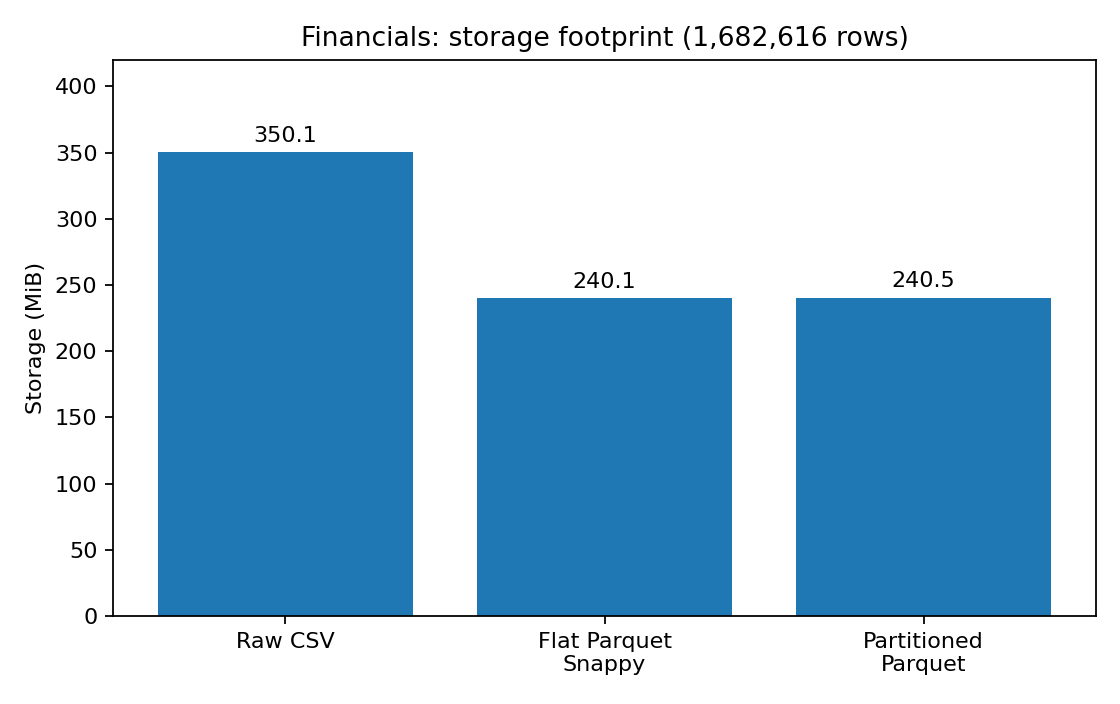

**Read Time Medians**

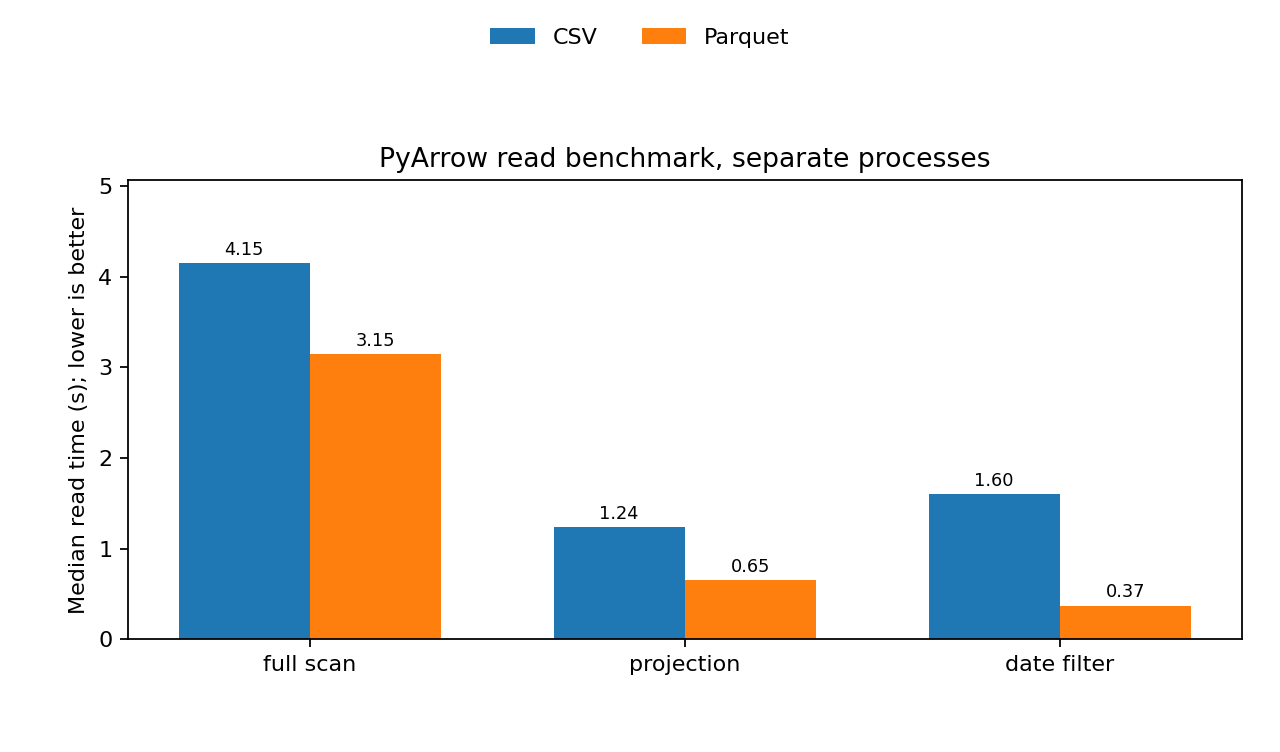

**Peak Rss Medians**

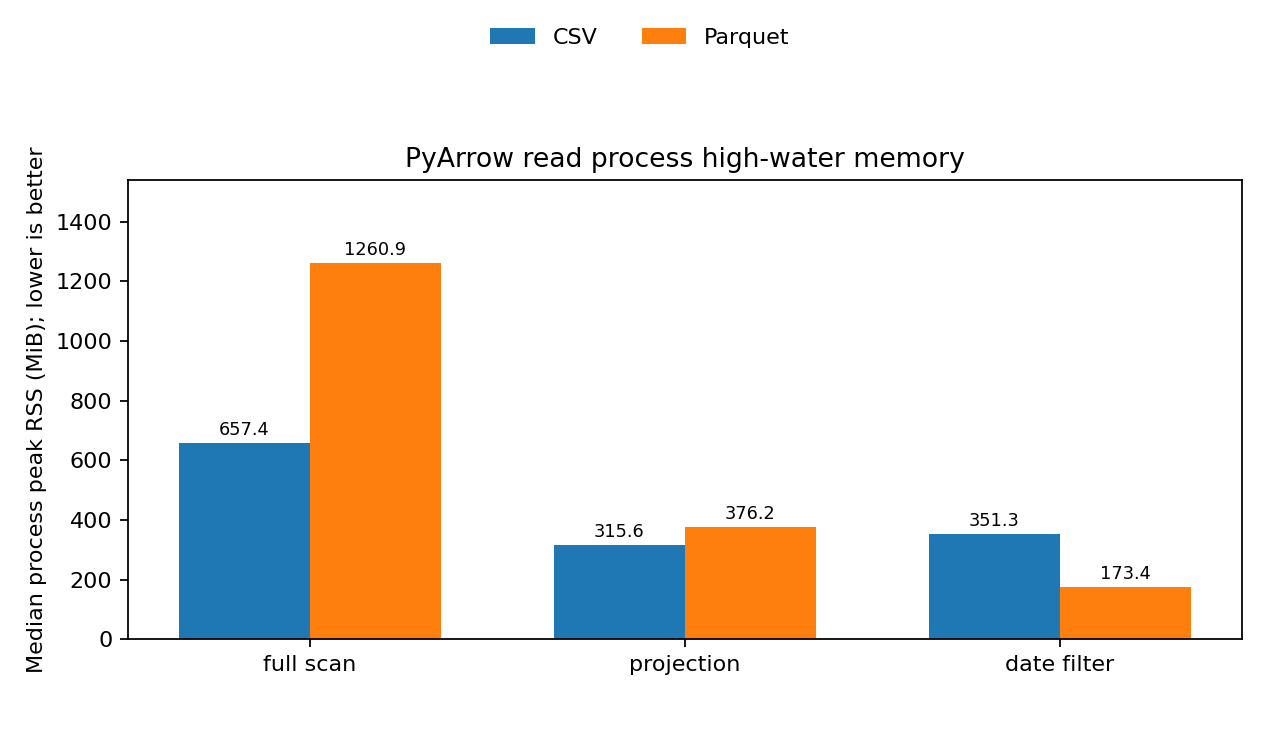

**Layout Scan Times**

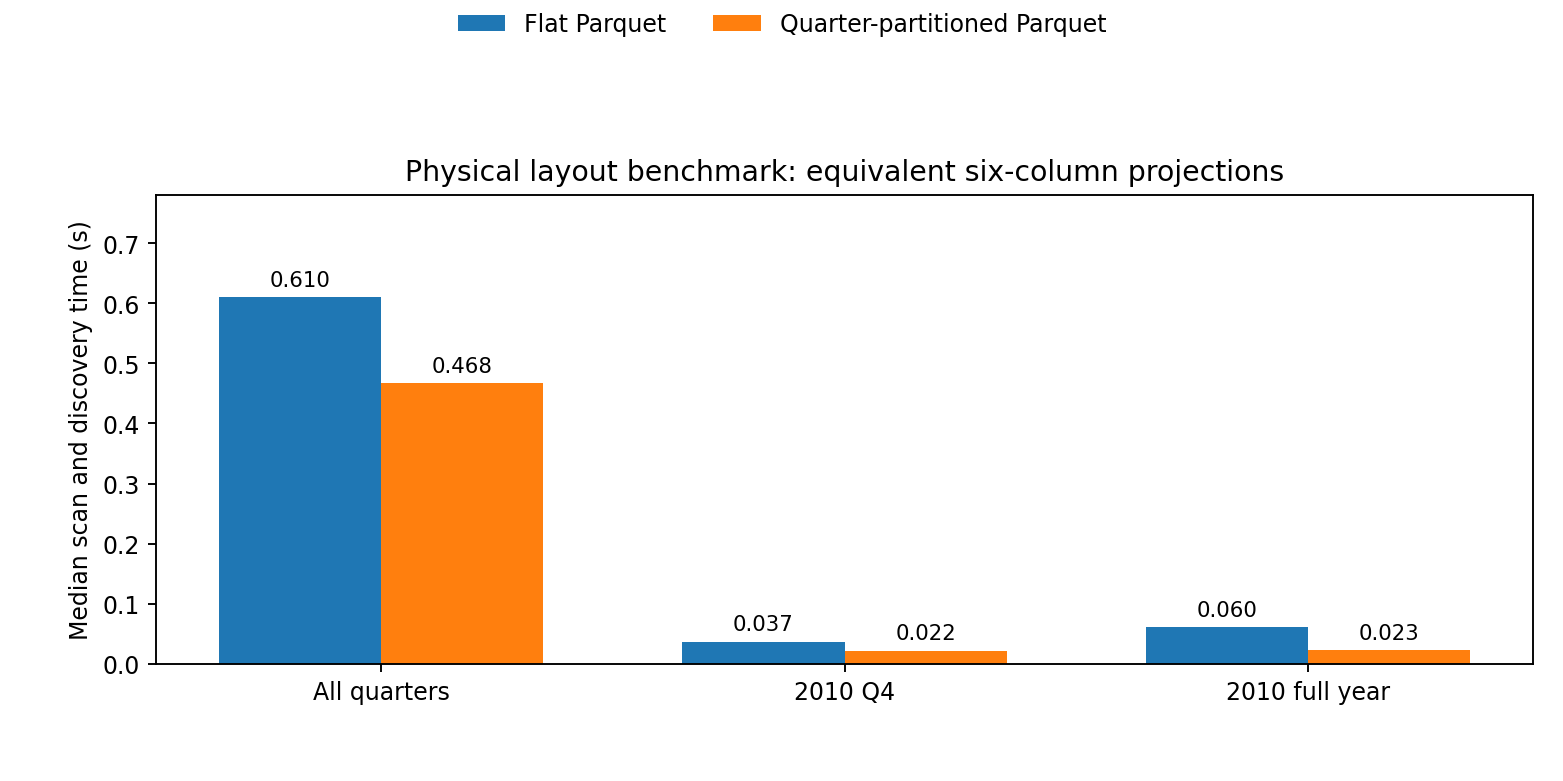

In [8]:
import csv
from IPython.display import display, Image, Markdown

for title, file in [
    ("Storage sizes", BENCHMARK_DIR / "storage_sizes.csv"),
    ("CSV versus flat Parquet", BENCHMARK_DIR / "comparisons.csv"),
    ("Flat versus partitioned Parquet", LAYOUT_DIR / "layout_summary.csv"),
]:
    display(Markdown("**" + title + "**"))
    with file.open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    keys = list(rows[0])
    display(Markdown(" | ".join(keys) + "\n" + " | ".join(["---"] * len(keys)) +
        "\n" + "\n".join(" | ".join(str(r[k]) for k in keys) for r in rows)))

for fig in (BENCHMARK_DIR / "storage_sizes.png",
            BENCHMARK_DIR / "read_time_medians.png",
            BENCHMARK_DIR / "peak_rss_medians.png",
            LAYOUT_DIR / "layout_scan_times.png"):
    display(Markdown("**" + fig.stem.replace("_", " ").title() + "**"))
    display(Image(filename=str(fig), width=800))

### 9. Part 2 input contract

The next computational stage reads `resolve_stage(DRIVE_ROOT, "acquisition")` for the typed Financials, Failures and Institutions sources, and `resolve_stage(DRIVE_ROOT, "storage")` for verified storage evidence. It must verify source checksums before generating a cleaned panel. Future failure events and current Institutions status are not contemporaneous predictor fields.

In [9]:
DATA_HANDOFF = resolve_stage(DRIVE_ROOT, "acquisition")
EVIDENCE_HANDOFF = resolve_stage(DRIVE_ROOT, "storage")
assert DATA_HANDOFF["validation"]["success"]
assert EVIDENCE_HANDOFF["validation"]["success"]
print("Input for Part 2:", DATA_HANDOFF["path"])
print("Storage evidence:", EVIDENCE_HANDOFF["path"])
print("Pinned repository commit:", GIT_COMMIT)
print("Handoff state: PASSED")

Input for Part 2: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/acquisition
Storage evidence: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/storage
Pinned repository commit: c5bad10b9199fe163ae7e1e1c1d9029a4be0c470
Handoff state: PASSED
